# 현재 구간만 사용하는 장기 이상 탐지 모델

정상 분포를 집단의 정상 분위수에 맞춰 보정한 최신 고정 후보다. 선택한 감시 구간 밖의 로그·누적 상태는 사용하지 않는다. 정상 참고 통계 28일은 별도로 요구한다.

**전체 목표는 아직 미달이다.** 1시간 F1 중앙값은 65%를 넘었지만 Recall 중앙값은 부족하다. 평가셋·정답·주입 강도를 바꾸지 않았다.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image, Markdown
cwd=Path.cwd()
ROOT=next(p for p in [cwd,*cwd.parents] if (p/'data/evaluation_long_term/manifest.json').exists())
if str(ROOT/'code') not in sys.path: sys.path.insert(0,str(ROOT/'code'))
from long_term_anomaly.common import read_json
from long_term_anomaly.report import TASKS
OUT=ROOT/'reports/long_term_anomaly/strict_alignment'
results=read_json(OUT/'results.json'); previous=read_json(ROOT/'reports/long_term_anomaly/strict_refinement/results.json')
labels=dict(accuracy='Accuracy',precision='Precision',recall='Recall',f1='F1')
pd.options.display.float_format='{:.2f}'.format
def table(mode='median'):
    return pd.DataFrame([{'구간':f'{h}시간',**{label:100*r[mode][m] for m,label in labels.items()},
        '전체 오탐률':100*r['pooled']['false_positive_rate'],
        '최대 시나리오 오탐률':100*r['maximum_scenario_fpr']} for h,r in results['results'].items()])
display(Markdown(f"동일한 **{results['results']['1']['pooled']['assessed_hours']:,}개 관측 시간**을 각 길이에서 평가했다. 전체 목표 달성: **{results['goal_met_all_lengths']}**."))

동일한 **192,178개 관측 시간**을 각 길이에서 평가했다. 전체 목표 달성: **False**.

## 1. 현재 성능

Accuracy·Precision·Recall·F1은 여섯 시나리오에서 각각 계산한 지표의 중앙값이다. 모든 개별 시나리오가 이 수치라는 뜻이 아니다. 각 지표의 중앙값을 따로 계산하므로 중앙값 Precision·Recall로 다시 계산한 F1과도 다를 수 있다.

목표는 각 구간 길이의 네 지표 중앙값 각각 65% 이상, 전체·각 시나리오 오탐률 6% 이하다. 정답 확장·point adjustment·어려운 시나리오 제외는 하지 않았다. 그림에 최소 목표선은 넣지 않았다.

,구간,Accuracy,Precision,Recall,F1,전체 오탐률,최대 시나리오 오탐률
0,1시간,88.89,70.69,61.01,65.49,5.33,5.77
1,4시간,90.94,75.93,69.67,72.74,3.72,4.69
2,8시간,92.29,80.88,75.95,75.87,3.71,5.37
3,12시간,92.81,78.38,76.53,77.39,4.14,5.17
4,24시간,93.44,78.23,80.90,79.86,3.89,5.64


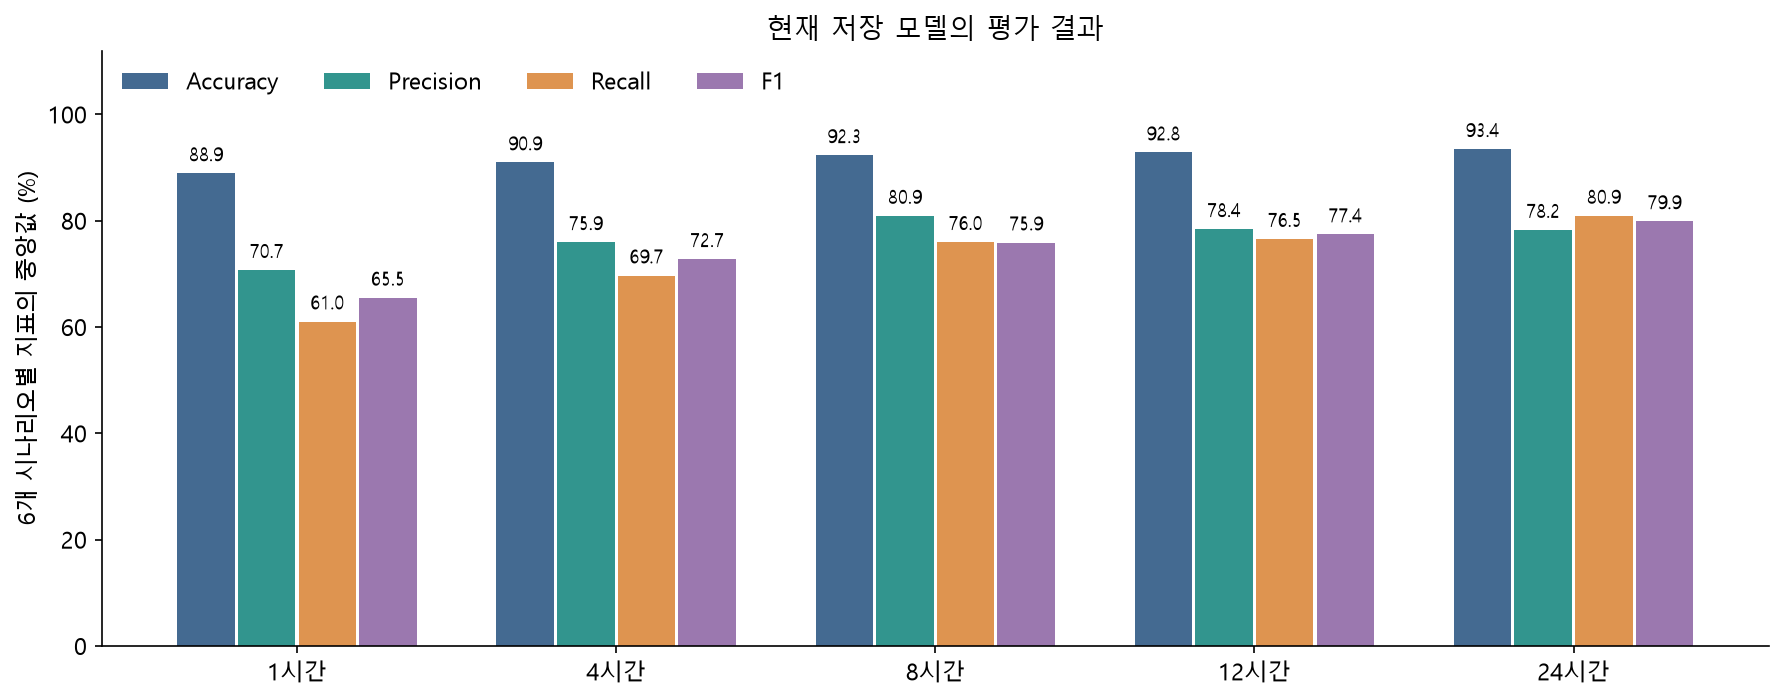

In [2]:
display(table())
display(Image(filename=str(OUT/'figures/metrics_median.png')))

## 2. 1시간 모델에서 바꾼 것

1. 정상 train 64개 구간의 앞 672시간만으로 정상 분포와 변동 폭의 공통 기준을 학습했다.
2. 실행 횟수의 변동 폭은 공통 기준으로, 소요시간의 변동 폭은 집단 기준 25%·공통 기준 75%의 분산 결합으로 안정화했다.
3. 각 집단의 과거 정상 1·5·25·50·75·95·99% 분위수와 학습한 정상 분포의 분위수를 맞췄다. 소요시간에만 25%의 약한 보정을 적용했다.
4. 보정한 현재 값이 정상 분포보다 일반적인 수준 이동·분포 확대 가설에 더 그럴듯한지 비교한다.

개별 감시값들로 분포를 재학습하지 않는다. 소요시간 보정은 정상 참고 통계로 만든 변환이며 실제 CSV 값을 수정한 것이 아니다. 4·8·12·24시간 모델과 모든 점수는 이전과 같다.

,항목,값
0,정상 학습 구간,64.00
1,정상 참고 길이(시간),672.00
2,실행 횟수 집단 분산 비중,0.00
3,소요시간 집단 분산 비중,0.25
4,소요시간 분위수 보정 강도,0.25
5,실제 경보 threshold,1.98


실제 경보 기준은 **1.98271326 초과**다. 점수 분포 그림에서는 기준을 1로 정규화했다.

,지표,이전 중앙값(%),현재 중앙값(%),변화(%p)
0,Accuracy,88.69,88.89,0.20
1,Precision,70.27,70.69,0.43
2,Recall,59.72,61.01,1.29
3,F1,64.56,65.49,0.93


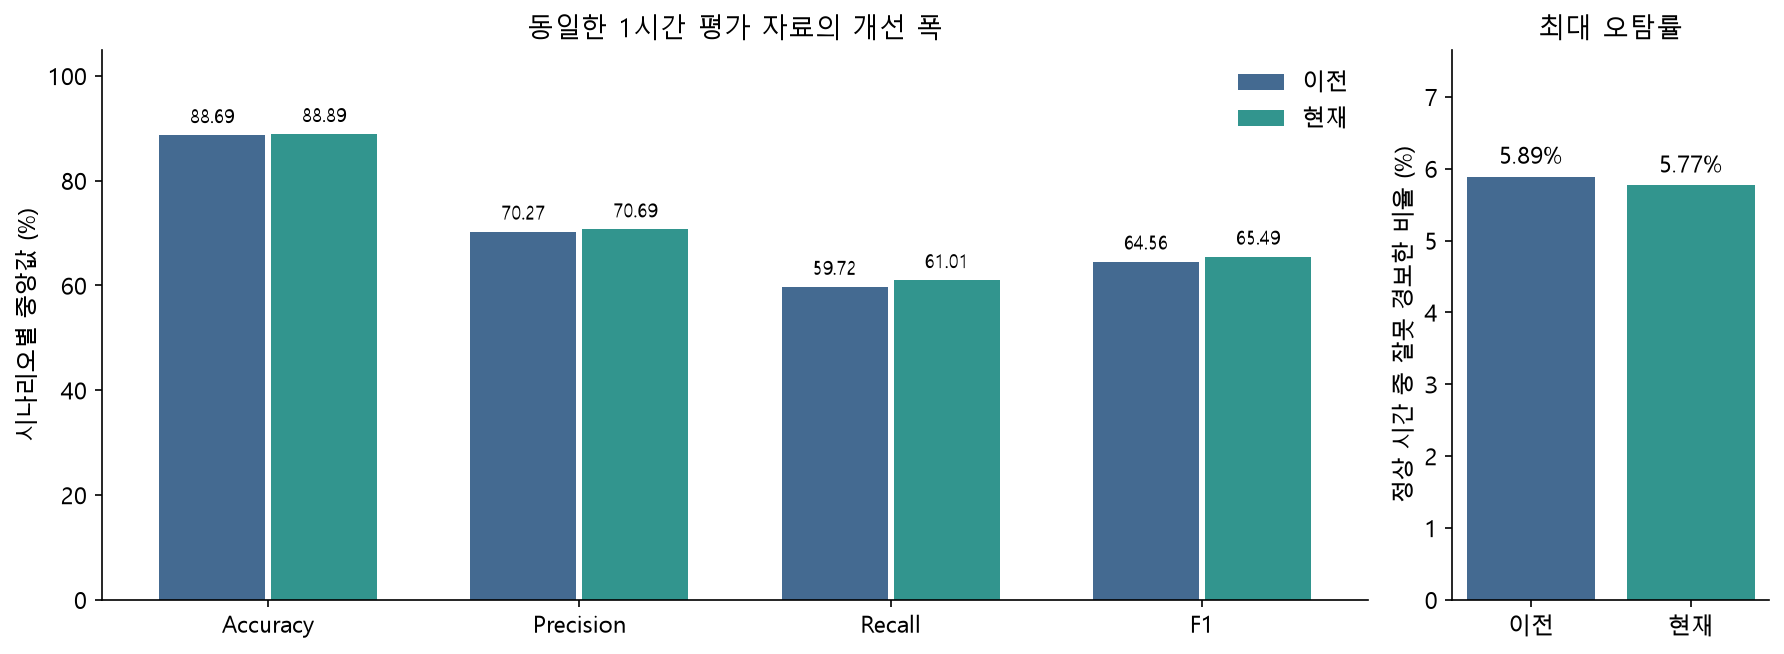

In [3]:
cal=read_json(OUT/'calibration.json')
cfg=cal['record']['one_hour_config']
display(pd.DataFrame([{'항목':'정상 학습 구간','값':64},{'항목':'정상 참고 길이(시간)','값':672},
    {'항목':'실행 횟수 집단 분산 비중','값':cfg['scale_alpha'][0]},
    {'항목':'소요시간 집단 분산 비중','값':cfg['scale_alpha'][1]},
    {'항목':'소요시간 분위수 보정 강도','값':cfg['alignment_strength'][1]},
    {'항목':'실제 경보 threshold','값':cfg['threshold']}]))
display(Markdown(f"실제 경보 기준은 **{cfg['threshold']:.8f} 초과**다. 점수 분포 그림에서는 기준을 1로 정규화했다."))
display(pd.DataFrame([{'지표':label,'이전 중앙값(%)':100*previous['results']['1']['median'][m],
    '현재 중앙값(%)':100*results['results']['1']['median'][m],
    '변화(%p)':100*(results['results']['1']['median'][m]-previous['results']['1']['median'][m])} for m,label in labels.items()]))
display(Image(filename=str(OUT/'figures/one_hour_change.png')))

## 3. 시나리오별 강점과 약점

Recall은 실제 이상을 얼마나 놓치지 않았는지, F1은 Recall과 경보 정확도의 균형을 보여준다. Accuracy만 높다고 이상을 잘 잡은 것은 아니다.

중앙값이 통과한 구간도 개별 시나리오는 약할 수 있다. 특히 4시간 입력 감소와 24시간 일일 패턴 변화의 약점은 그대로 남는다. 1시간은 한 점의 수준 차이를 비교하며 구간 안의 증가 추세나 지속성을 직접 측정한 것은 아니다.

,시나리오,Accuracy,Precision,Recall,F1,오탐률
0,일일 패턴 변화,80.27,69.40,37.58,48.76,5.52
1,점진적 악화,87.65,70.95,59.75,64.87,5.77
2,지속 지연,90.92,72.61,72.47,72.54,5.42
3,지속 입력 감소,90.13,70.43,62.27,66.10,4.78
4,지속 폭주,91.81,74.14,73.30,73.72,4.75
5,변동성 증가,85.43,53.88,37.03,43.90,5.77


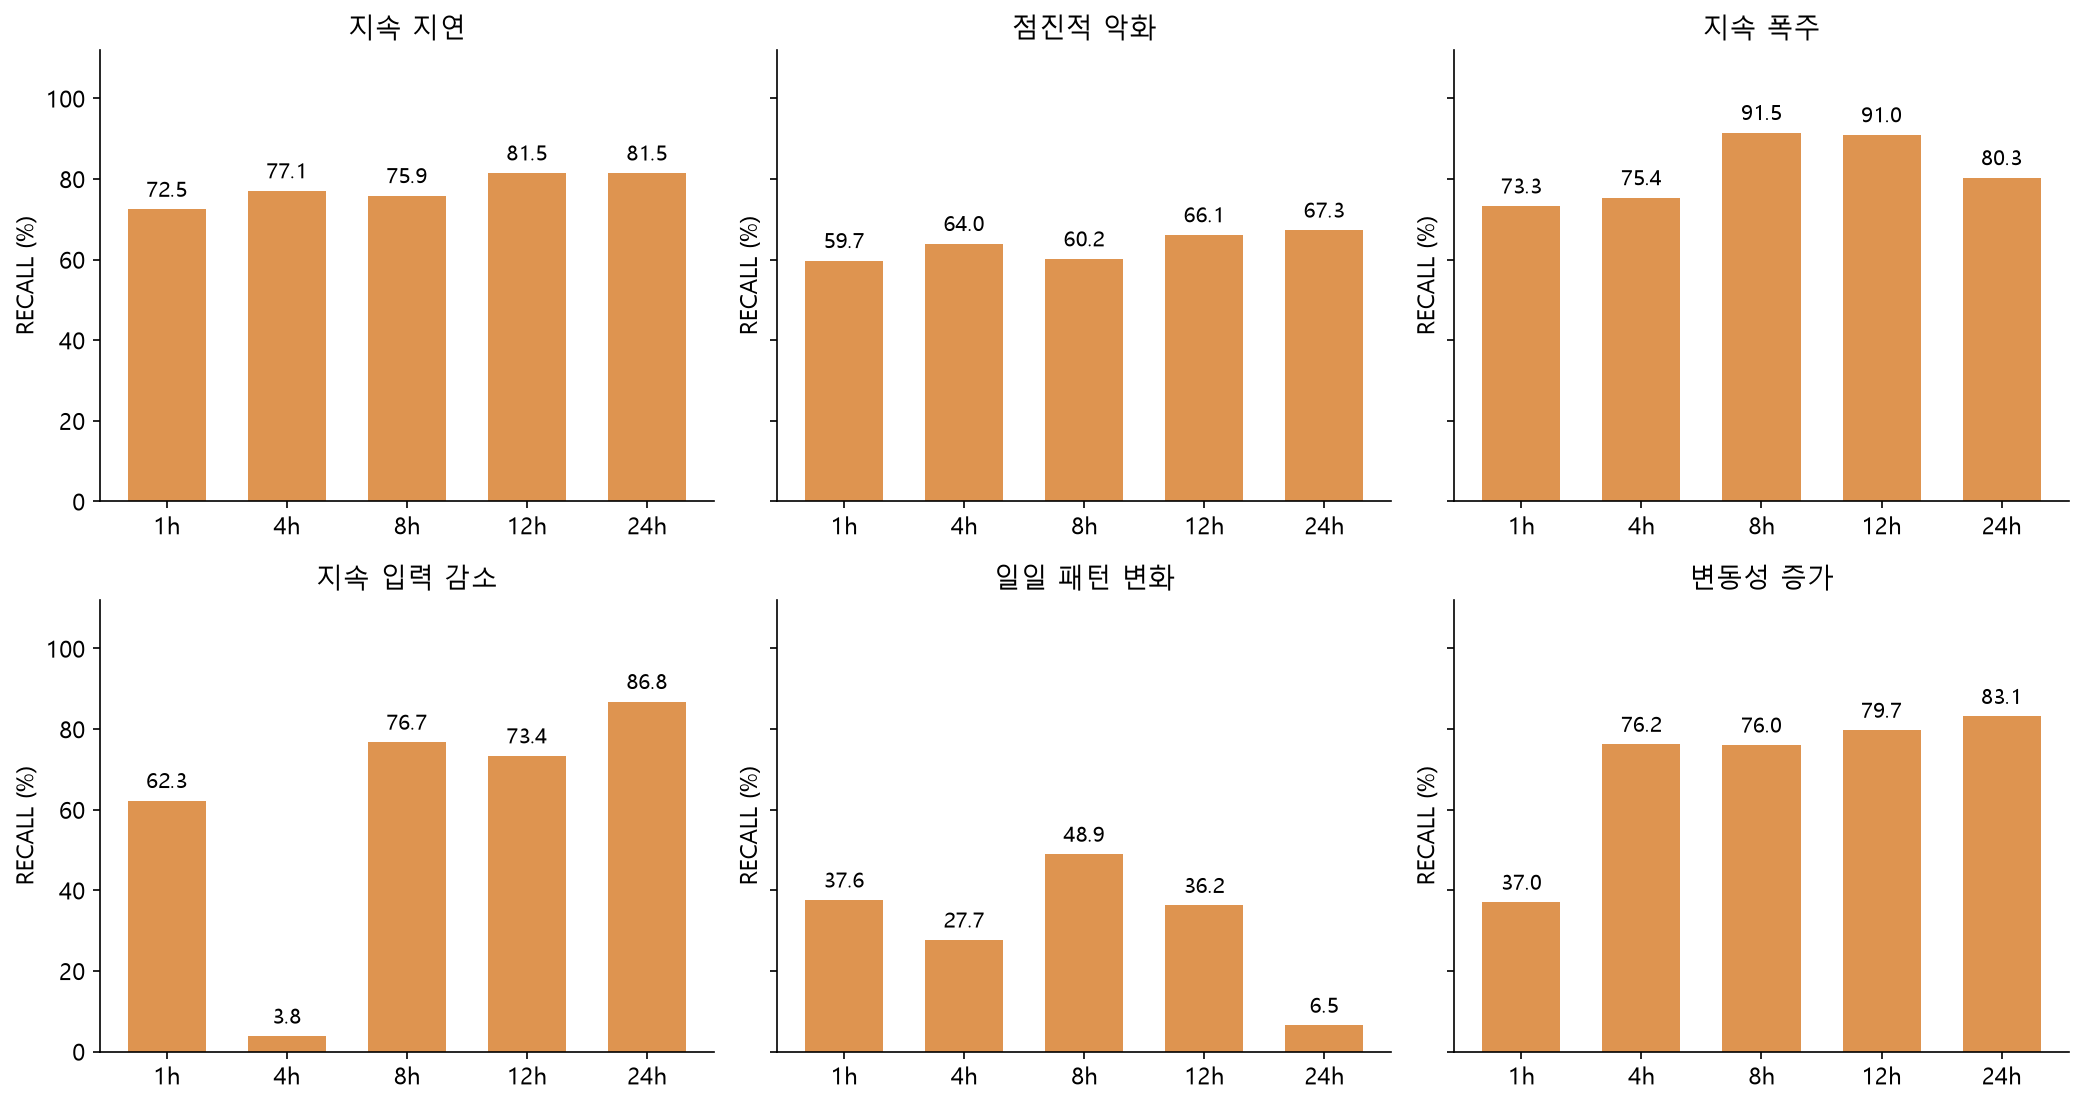

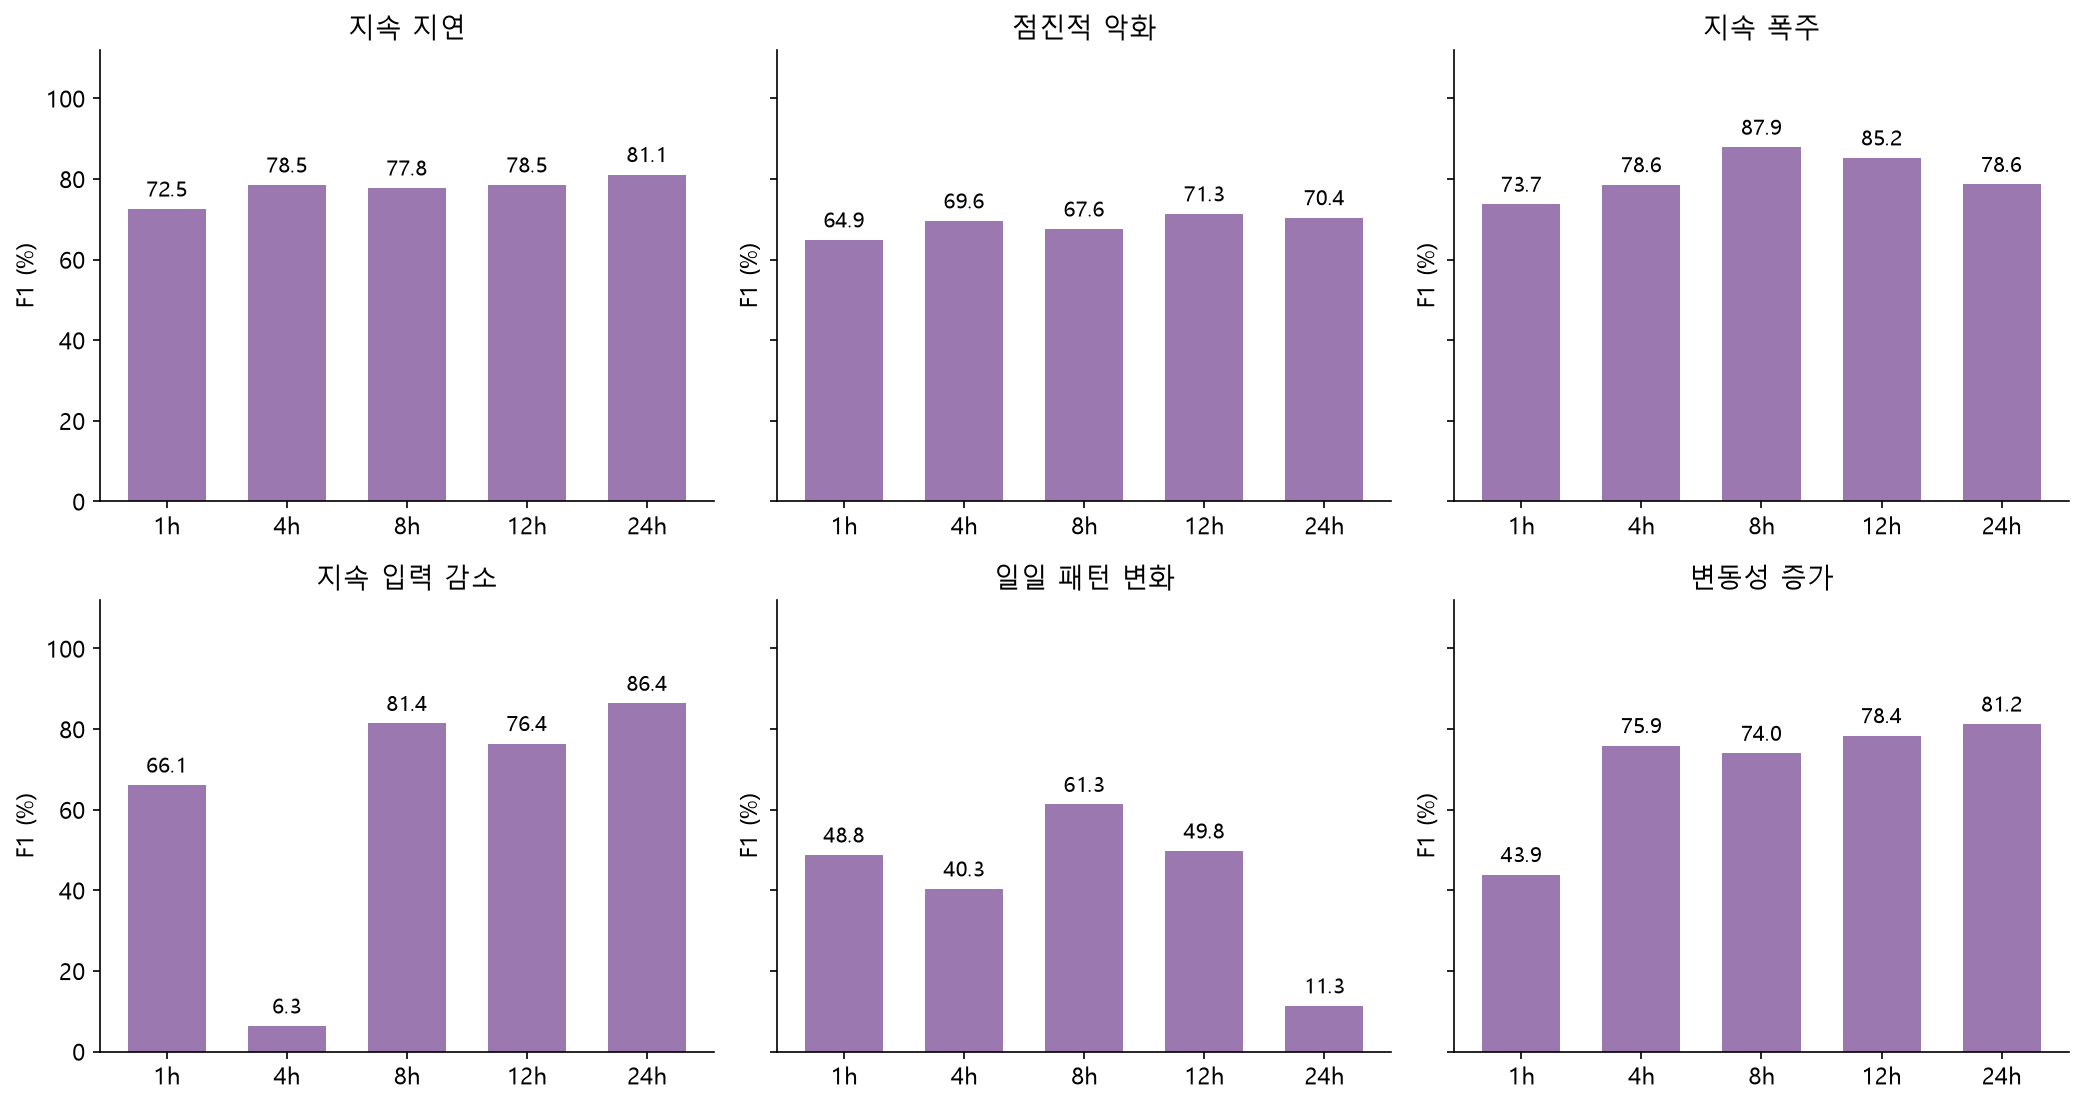

In [4]:
display(pd.DataFrame([{'시나리오':TASKS[t],**{label:100*v[m] for m,label in labels.items()},
    '오탐률':100*v['false_positive_rate']} for t,v in results['results']['1']['scenarios'].items()]))
display(Image(filename=str(OUT/'figures/scenario_recall.png')))
display(Image(filename=str(OUT/'figures/scenario_f1.png')))

## 4. 점수 분포와 실제 경보 기준

점수를 실제 threshold로 나눴다. 1을 초과하면 경보다. 점수는 확률이 아니며 음수도 가능하다. 정상과 이상 분포는 각각 100%로 정규화했다. 동일한 축으로 비교하고 범위 밖 값은 양끝 막대에 포함했다.

색은 보고서용 정답이며 모델 입력이 아니다. 실제 평가는 원래 모든 점수를 사용했다. 경보의 reason은 가장 크게 기여한 통계 가설이며 장애의 확정 원인은 아니다.

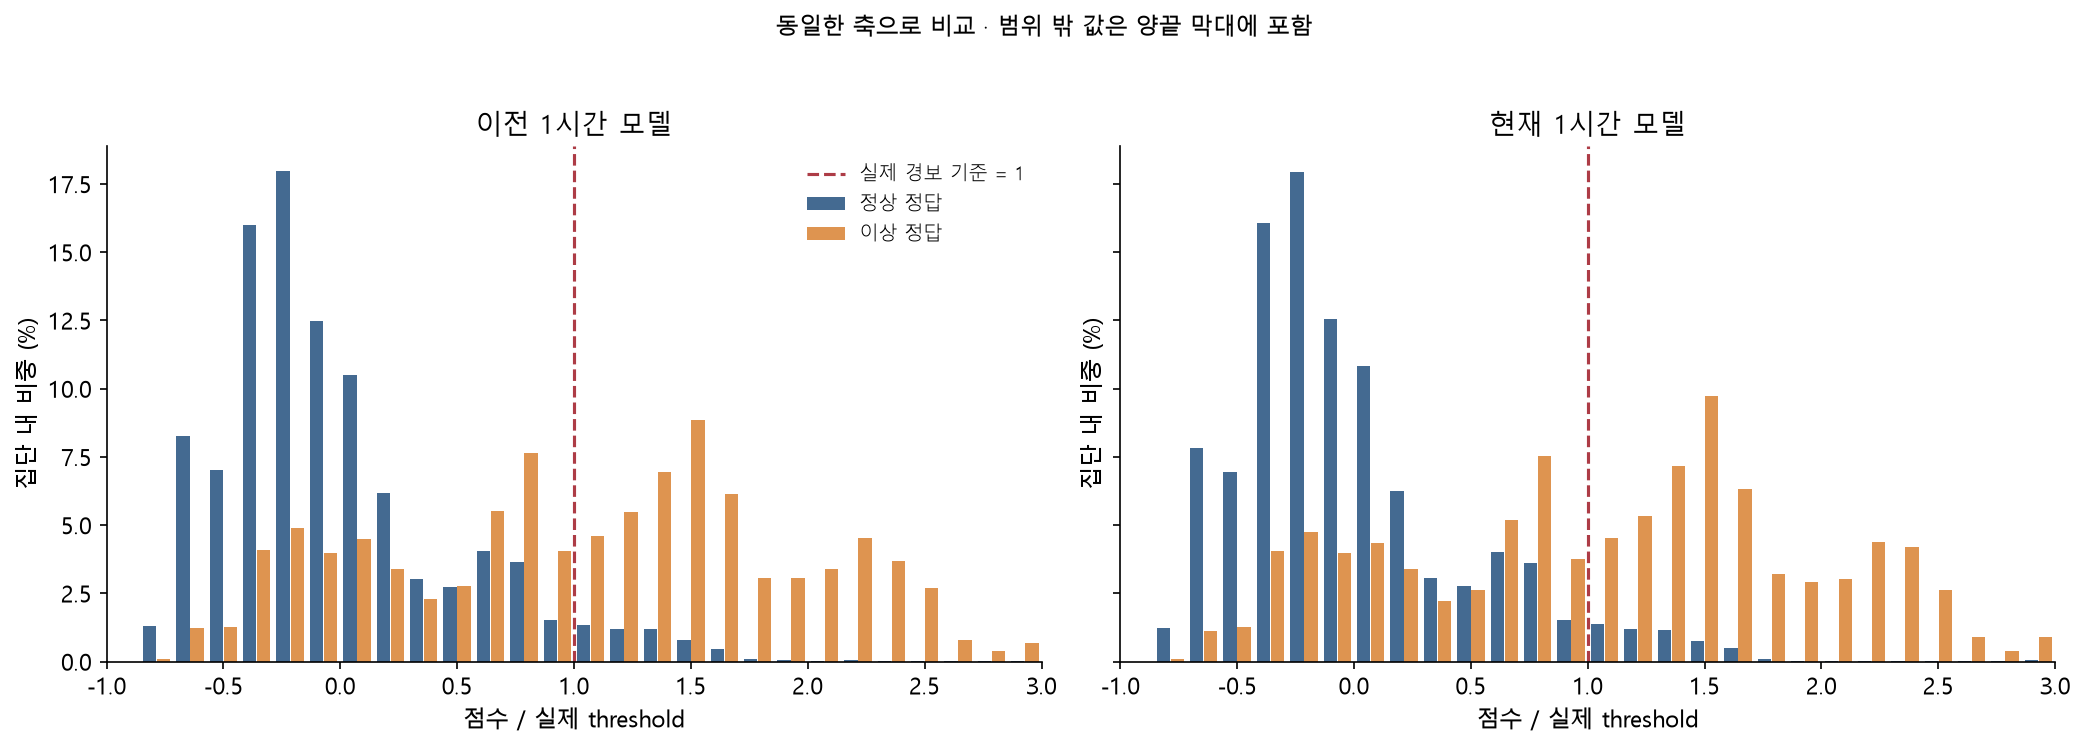

In [5]:
display(Image(filename=str(OUT/'figures/score_distribution.png')))

## 5. 통합 지표와 중앙값 구분

아래는 모든 관측 시간의 혼동행렬을 합쳐 계산한 지표다. 앞의 시나리오별 중앙값과 다르며 두 결과를 함께 봐야 한다.

In [6]:
display(table('pooled'))

,구간,Accuracy,Precision,Recall,F1,전체 오탐률,최대 시나리오 오탐률
0,1시간,87.70,69.42,55.63,61.76,5.33,5.77
1,4시간,88.42,75.33,52.27,61.72,3.72,4.69
2,8시간,91.46,80.22,69.23,74.32,3.71,5.37
3,12시간,90.92,78.15,68.17,72.82,4.14,5.17
4,24시간,90.08,77.68,62.33,69.16,3.89,5.64


## 6. 검증과 사용법

개발셋에서 선택한 후보 하나를 고정하고 테스트했다. 원래 테스트는 이미 보고된 평가집단이므로 새 독립 블라인드 평가가 아니다. 정상·평가 CSV 및 정답의 해시, 모든 지표의 독립 재계산, 30개 전체 backend API 재생을 확인했다.

```python
from long_term_anomaly.strict_alignment.model import load_bank
bank = load_bank('reports/long_term_anomaly/strict_alignment/models.joblib')
reference = bank.prepare_reference(normal_history_28days)
result = bank.predict_batch(reference, selected_batch, analysis_hours=1)
```

1·4·8·12·24시간을 고를 수 있고 정확히 H개의 시간별 집계 행을 입력한다. 원본 Process 행을 그대로 넣는 API가 아니다. 이전 감시 배치를 참고하지 않으며 감시 자료를 정상 참고 자료에 자동 편입하지 않는다.

In [7]:
verification=read_json(OUT/'validation.json')
display(pd.DataFrame([{'검증':k,'확인':v} for k,v in verification['checks'].items()]))
display(pd.DataFrame([{'구간':f'{h}시간','네 지표 중앙값·오탐률 목표 충족':v} for h,v in verification['goal_per_length'].items()]))
display(Markdown(f"무결성 검증: **{verification['integrity_passed']}**. 전체 성능 목표: **{verification['goal_met_all_lengths']}**. 서로 다른 조건이다."))

,검증,확인
0,all_previous_source_data_models_and_reports_pr...,True
1,all_three_original_period_files_unchanged,True
2,model_source_selection_protocol_and_prediction...,True
3,single_development_selected_candidate_and_reus...,True
4,all_original_observed_hours_and_all_six_scenar...,True
5,all_35_confusion_matrices_and_all_metric_media...,True
6,other_four_horizon_scores_exactly_unchanged,True
7,thirty_complete_backend_api_replays_without_fi...,True
8,no_other_monitoring_batch_or_automatic_referen...,True


,구간,네 지표 중앙값·오탐률 목표 충족
0,1시간,False
1,4시간,True
2,8시간,True
3,12시간,True
4,24시간,True


무결성 검증: **True**. 전체 성능 목표: **False**. 서로 다른 조건이다.

## 근거와 남은 한계

[Bühlmann의 AR 잔차 재표본 원리](https://statistics.berkeley.edu/sites/default/files/tech-reports/431.pdf)를 참고한 정상 분포 학습에 분위수 보정을 추가했다. 원 논문 알고리즘이나 이론 보장을 그대로 재현한 것은 아니다.

평가셋의 정상 연속성도 AR형으로 생성되어 모델에 유리할 수 있다. 실제 운영 장애 성능은 별도 검증이 필요하다. STATUS=S가 실제 정상의 보장은 아니므로 운영 정상 참고 구간은 검토해야 한다.

1시간 입력은 한 점이며 여전히 Recall이 목표에 부족하다. 더 촘촘한 입력 해상도 변경은 적용하지 않았다. 전체 목표를 달성했다고 처리하지 않는다.